In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_csv("bank.csv", sep=";")


In [21]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [22]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
4114,30,admin.,married,basic.6y,no,yes,yes,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.958,5228.1,no
4115,39,admin.,married,high.school,no,yes,no,telephone,jul,fri,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.959,5228.1,no
4116,27,student,single,high.school,no,no,no,cellular,may,mon,...,2,999,1,failure,-1.8,92.893,-46.2,1.354,5099.1,no
4117,58,admin.,married,high.school,no,no,no,cellular,aug,fri,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no
4118,34,management,single,high.school,no,yes,no,cellular,nov,wed,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no


In [23]:
df.shape

(4119, 21)

In [24]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   object 
 2   marital         4119 non-null   object 
 3   education       4119 non-null   object 
 4   default         4119 non-null   object 
 5   housing         4119 non-null   object 
 6   loan            4119 non-null   object 
 7   contact         4119 non-null   object 
 8   month           4119 non-null   object 
 9   day_of_week     4119 non-null   object 
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   object 
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   f

In [26]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [27]:
df.duplicated().sum()

0

In [35]:
df['job'].value_counts()

admin.           1012
blue-collar       884
technician        691
services          393
management        324
retired           166
self-employed     159
entrepreneur      148
unemployed        111
housemaid         110
student            82
unknown            39
Name: job, dtype: int64

In [34]:
df['age'].mean()

40.11361981063365

In [36]:
df['housing'].value_counts()

yes        2175
no         1839
unknown     105
Name: housing, dtype: int64

In [37]:
df['y'].value_counts()

no     3668
yes     451
Name: y, dtype: int64

In [38]:
len(df)

4119

In [39]:
df['y'].value_counts()

no     3668
yes     451
Name: y, dtype: int64

In [40]:
subscription_rate = (df['y'] == 'yes').mean() * 100

print(f"Subscription Rate: {subscription_rate:.2f}%")

Subscription Rate: 10.95%


In [41]:
non_subscription_rate = (df['y'] == 'no').mean() * 100

print(f"Non-subscription Rate: {non_subscription_rate:.2f}%")

Non-subscription Rate: 89.05%


In [42]:
df['job'].unique()

array(['blue-collar', 'services', 'admin.', 'entrepreneur',
       'self-employed', 'technician', 'management', 'student', 'retired',
       'housemaid', 'unemployed', 'unknown'], dtype=object)

In [43]:
df['job'].value_counts()

admin.           1012
blue-collar       884
technician        691
services          393
management        324
retired           166
self-employed     159
entrepreneur      148
unemployed        111
housemaid         110
student            82
unknown            39
Name: job, dtype: int64

In [45]:
occupation_analysis = df.groupby('job')['y'].value_counts().unstack(fill_value=0)

occupation_analysis

y,no,yes
job,,
admin.,879,133
blue-collar,823,61
entrepreneur,140,8
housemaid,99,11
management,294,30
retired,128,38
self-employed,146,13
services,358,35
student,63,19


In [46]:
occupation_analysis['total_customers'] = (
    occupation_analysis['yes'] + occupation_analysis['no']
)

occupation_analysis['subscription_rate'] = (
    occupation_analysis['yes'] /
    occupation_analysis['total_customers'] * 100
)

occupation_analysis

y,no,yes,total_customers,subscription_rate
job,,,,
admin.,879,133,1012,13.142292
blue-collar,823,61,884,6.900452
entrepreneur,140,8,148,5.405405
housemaid,99,11,110,10.000000
management,294,30,324,9.259259
retired,128,38,166,22.891566
self-employed,146,13,159,8.176101
services,358,35,393,8.905852
student,63,19,82,23.170732


In [47]:
occupation_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

y,no,yes,total_customers,subscription_rate
job,,,,
student,63,19,82,23.170732
retired,128,38,166,22.891566
unemployed,92,19,111,17.117117
admin.,879,133,1012,13.142292
technician,611,80,691,11.577424
unknown,35,4,39,10.256410
housemaid,99,11,110,10.000000
management,294,30,324,9.259259
services,358,35,393,8.905852


In [48]:
occupation_analysis.loc['student']

y
no                   63.000000
yes                  19.000000
total_customers      82.000000
subscription_rate    23.170732
Name: student, dtype: float64

In [49]:
occupation_analysis.loc['student', 'yes']

19

In [50]:
occupation_analysis.loc['student', 'total_customers']

82

In [51]:
occupation_analysis.sort_values(
    by='yes',
    ascending=False
)

y,no,yes,total_customers,subscription_rate
job,,,,
admin.,879,133,1012,13.142292
technician,611,80,691,11.577424
blue-collar,823,61,884,6.900452
retired,128,38,166,22.891566
services,358,35,393,8.905852
management,294,30,324,9.259259
student,63,19,82,23.170732
unemployed,92,19,111,17.117117
self-employed,146,13,159,8.176101


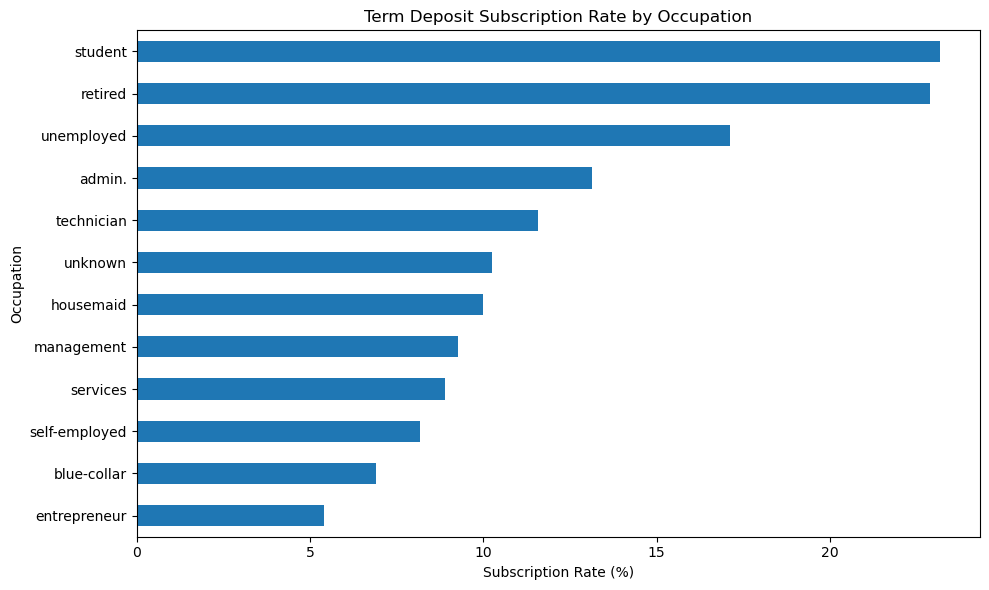

In [52]:
occupation_analysis['subscription_rate'].sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    title='Term Deposit Subscription Rate by Occupation'
)

plt.xlabel('Subscription Rate (%)')
plt.ylabel('Occupation')
plt.tight_layout()
plt.show()

In [54]:
occupation_analysis.loc[
    ['student', 'admin.'],
    ['yes', 'no', 'total_customers', 'subscription_rate']
]

y,yes,no,total_customers,subscription_rate
job,,,,
student,19,63,82,23.170732
admin.,133,879,1012,13.142292


In [56]:
df['age'].describe()

count    4119.000000
mean       40.113620
std        10.313362
min        18.000000
25%        32.000000
50%        38.000000
75%        47.000000
max        88.000000
Name: age, dtype: float64

In [58]:
bins = [0, 24, 34, 44, 54, float('inf')]

labels = [
    'Below 25',
    '25-34',
    '35-44',
    '45-54',
    '55 and above'
]

df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels
)

In [59]:
df['age_group'].value_counts().sort_index()

Below 25          98
25-34           1381
35-44           1327
45-54            886
55 and above     427
Name: age_group, dtype: int64

In [60]:
age_analysis = df.groupby(
    'age_group',
    observed=True
)['y'].value_counts().unstack(fill_value=0)

age_analysis

y,no,yes
age_group,,
Below 25,86,12
25-34,1220,161
35-44,1215,112
45-54,796,90
55 and above,351,76


In [61]:
age_analysis['total_customers'] = (
    age_analysis['yes'] + age_analysis['no']
)

age_analysis['subscription_rate'] = (
    age_analysis['yes'] /
    age_analysis['total_customers'] * 100
)

age_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

y,no,yes,total_customers,subscription_rate
age_group,,,,
55 and above,351,76,427,17.798595
Below 25,86,12,98,12.244898
25-34,1220,161,1381,11.658219
45-54,796,90,886,10.158014
35-44,1215,112,1327,8.440090


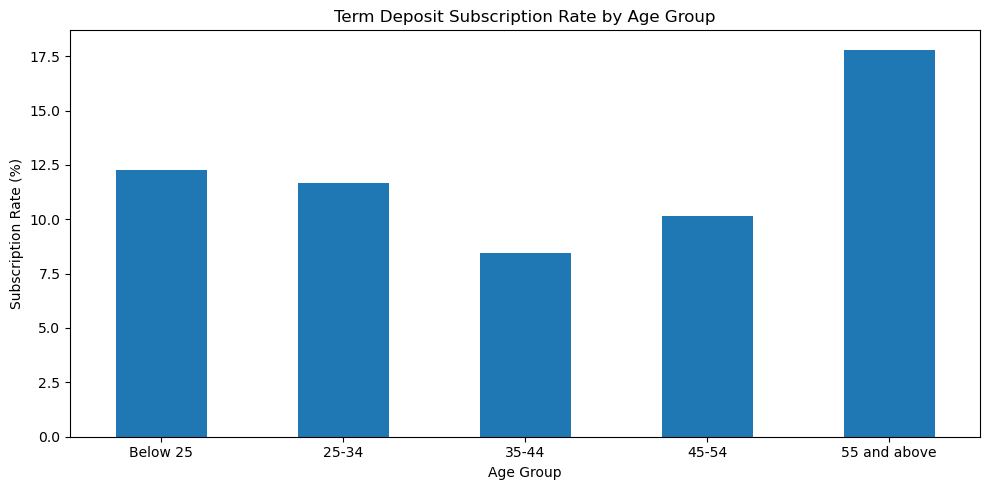

In [62]:
age_analysis['subscription_rate'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Term Deposit Subscription Rate by Age Group'
)

plt.xlabel('Age Group')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [63]:
age_analysis['subscription_contribution'] = (
    age_analysis['yes'] / df['y'].eq('yes').sum()
) * 100

age_analysis[
    ['yes', 'total_customers',
     'subscription_rate', 'subscription_contribution']
]

y,yes,total_customers,subscription_rate,subscription_contribution
age_group,,,,
Below 25,12,98,12.244898,2.660754
25-34,161,1381,11.658219,35.698448
35-44,112,1327,8.440090,24.833703
45-54,90,886,10.158014,19.955654
55 and above,76,427,17.798595,16.851441


In [64]:
df['housing'].value_counts()

yes        2175
no         1839
unknown     105
Name: housing, dtype: int64

In [65]:
housing_analysis = df.groupby('housing')['y'].value_counts().unstack(fill_value=0)

housing_analysis

y,no,yes
housing,,
no,1637,202
unknown,96,9
yes,1935,240


In [66]:
housing_analysis['total_customers'] = (
    housing_analysis['yes'] + housing_analysis['no']
)

housing_analysis['subscription_rate'] = (
    housing_analysis['yes'] /
    housing_analysis['total_customers'] * 100
)

housing_analysis

y,no,yes,total_customers,subscription_rate
housing,,,,
no,1637,202,1839,10.984231
unknown,96,9,105,8.571429
yes,1935,240,2175,11.034483


In [67]:
difference = (
    housing_analysis.loc['yes', 'subscription_rate']
    - housing_analysis.loc['no', 'subscription_rate']
)

print(f"Difference: {difference:.4f} percentage points")

Difference: 0.0503 percentage points


In [68]:
df['campaign'].describe()

count    4119.000000
mean        2.537266
std         2.568159
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        35.000000
Name: campaign, dtype: float64

In [69]:
df['campaign'].value_counts().sort_index()

1     1764
2     1039
3      549
4      291
5      142
6       99
7       60
8       36
9       32
10      20
11      19
12      16
13      11
14       6
15       2
16       7
17      14
18       1
19       2
22       2
23       2
24       1
27       1
29       2
35       1
Name: campaign, dtype: int64

In [70]:
campaign_analysis = df.groupby('campaign')['y'].value_counts().unstack(fill_value=0)

campaign_analysis.head(15)

y,no,yes
campaign,,
1,1545,219
2,920,119
3,487,62
4,259,32
5,133,9
6,95,4
7,59,1
8,34,2
9,31,1


In [71]:
campaign_analysis['total_customers'] = (
    campaign_analysis['yes'] + campaign_analysis['no']
)

campaign_analysis['subscription_rate'] = (
    campaign_analysis['yes'] /
    campaign_analysis['total_customers'] * 100
)

campaign_analysis.head(15)

y,no,yes,total_customers,subscription_rate
campaign,,,,
1,1545,219,1764,12.414966
2,920,119,1039,11.453321
3,487,62,549,11.293260
4,259,32,291,10.996564
5,133,9,142,6.338028
6,95,4,99,4.040404
7,59,1,60,1.666667
8,34,2,36,5.555556
9,31,1,32,3.125000


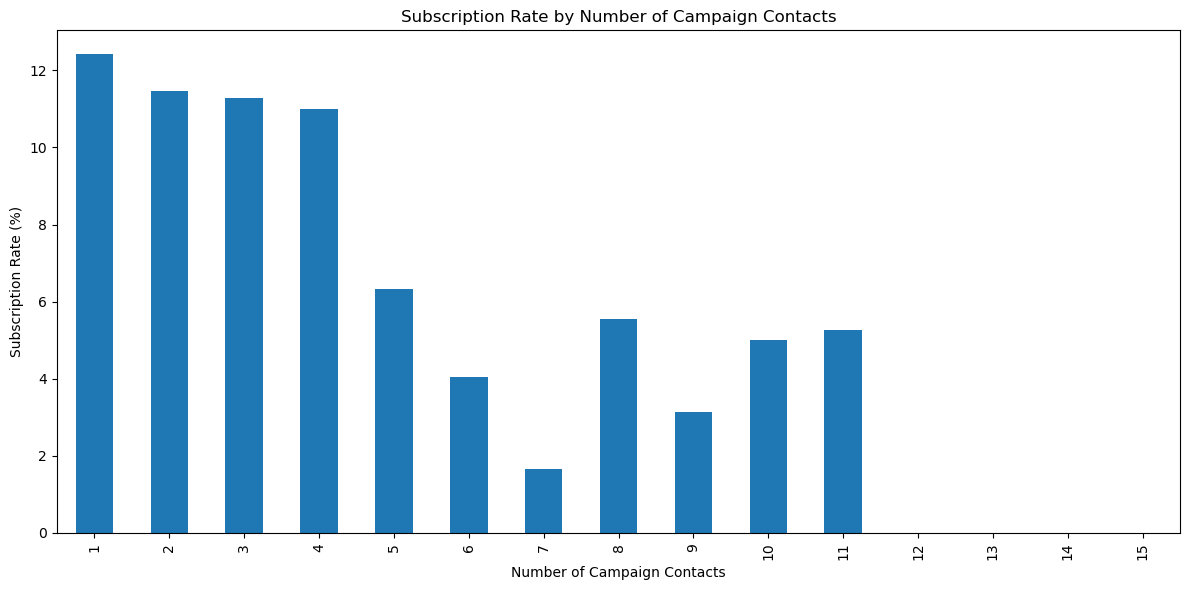

In [72]:
campaign_analysis['subscription_rate'].head(15).plot(
    kind='bar',
    figsize=(12, 6),
    title='Subscription Rate by Number of Campaign Contacts'
)

plt.xlabel('Number of Campaign Contacts')
plt.ylabel('Subscription Rate (%)')
plt.tight_layout()
plt.show()

In [73]:
campaign_analysis[
    ['yes', 'no', 'total_customers', 'subscription_rate']
].sort_values(
    by='campaign'
).head(15)

y,yes,no,total_customers,subscription_rate
campaign,,,,
1,219,1545,1764,12.414966
2,119,920,1039,11.453321
3,62,487,549,11.293260
4,32,259,291,10.996564
5,9,133,142,6.338028
6,4,95,99,4.040404
7,1,59,60,1.666667
8,2,34,36,5.555556
9,1,31,32,3.125000


In [74]:
campaign_analysis.sort_values(
    by='yes',
    ascending=False
).head(10)

y,no,yes,total_customers,subscription_rate
campaign,,,,
1,1545,219,1764,12.414966
2,920,119,1039,11.453321
3,487,62,549,11.293260
4,259,32,291,10.996564
5,133,9,142,6.338028
6,95,4,99,4.040404
8,34,2,36,5.555556
10,19,1,20,5.000000
11,18,1,19,5.263158


In [75]:
df['contact'].value_counts()

cellular     2652
telephone    1467
Name: contact, dtype: int64

In [76]:
contact_analysis = df.groupby('contact')['y'].value_counts().unstack(fill_value=0)

contact_analysis

y,no,yes
contact,,
cellular,2277,375
telephone,1391,76


In [77]:
contact_analysis['total_customers'] = (
    contact_analysis['yes'] + contact_analysis['no']
)

contact_analysis['subscription_rate'] = (
    contact_analysis['yes'] /
    contact_analysis['total_customers'] * 100
)

contact_analysis

y,no,yes,total_customers,subscription_rate
contact,,,,
cellular,2277,375,2652,14.140271
telephone,1391,76,1467,5.180641


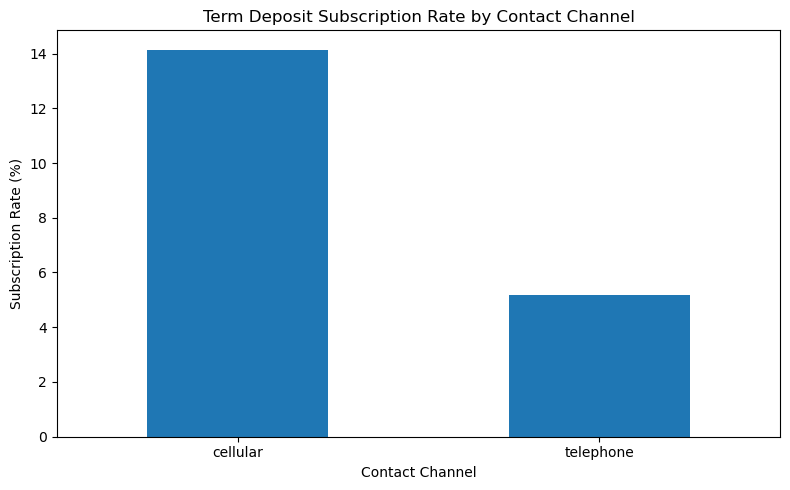

In [78]:
contact_analysis['subscription_rate'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Term Deposit Subscription Rate by Contact Channel'
)

plt.xlabel('Contact Channel')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [79]:
df['poutcome'].value_counts()

nonexistent    3523
failure         454
success         142
Name: poutcome, dtype: int64

In [80]:
previous_analysis = df.groupby('poutcome')['y'].value_counts().unstack(fill_value=0)

previous_analysis

y,no,yes
poutcome,,
failure,387,67
nonexistent,3231,292
success,50,92


In [81]:
previous_analysis['total_customers'] = (
    previous_analysis['yes'] + previous_analysis['no']
)

previous_analysis['subscription_rate'] = (
    previous_analysis['yes'] /
    previous_analysis['total_customers'] * 100
)

previous_analysis

y,no,yes,total_customers,subscription_rate
poutcome,,,,
failure,387,67,454,14.757709
nonexistent,3231,292,3523,8.288391
success,50,92,142,64.788732


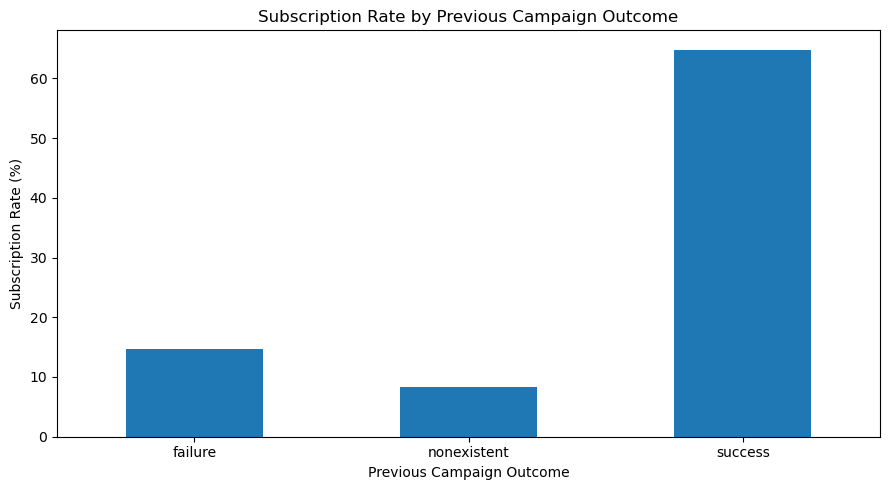

In [82]:
previous_analysis['subscription_rate'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Subscription Rate by Previous Campaign Outcome'
)

plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [83]:
df['subscribed'] = (df['y'] == 'yes').astype(int)


In [84]:
segment_analysis = df.groupby(
    ['age_group', 'poutcome'],
    observed=True
).agg(
    total_customers=('subscribed', 'count'),
    subscriptions=('subscribed', 'sum'),
    subscription_rate=('subscribed', 'mean')
)

segment_analysis['subscription_rate'] *= 100

segment_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

,,total_customers,subscriptions,subscription_rate
age_group,poutcome,,,
45-54,success,26,18,69.230769
35-44,success,34,23,67.647059
25-34,success,47,31,65.957447
55 and above,success,30,18,60.000000
Below 25,success,5,2,40.000000
55 and above,failure,61,13,21.311475
Below 25,failure,18,3,16.666667
45-54,failure,89,13,14.606742
25-34,failure,152,22,14.473684


In [85]:
channel_previous_analysis = df.groupby(
    ['poutcome', 'contact']
)['subscribed'].agg(
    total_customers='count',
    subscriptions='sum',
    subscription_rate='mean'
)

channel_previous_analysis['subscription_rate'] *= 100

channel_previous_analysis

total_customers  subscriptions  subscription_rate
poutcome    contact                                                     
failure     cellular               427             67          15.690867
            telephone               27              0           0.000000
nonexistent cellular              2094            223          10.649475
            telephone             1429             69           4.828551
success     cellular               131             85          64.885496
            telephone               11              7          63.636364

In [86]:
from scipy.stats import chi2_contingency

contact_test = pd.crosstab(df['contact'], df['y'])

chi2, p_value, dof, expected = chi2_contingency(contact_test)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 76.84623735533606
P-value: 1.8479997217891733e-18
Degrees of freedom: 1


In [87]:
import numpy as np

n = contact_test.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print("Cramer's V:", cramers_v)

Cramer's V: 0.13658890014016295


In [88]:
previous_test = pd.crosstab(
    df['poutcome'],
    df['y']
)

previous_test

y,no,yes
poutcome,,
failure,387,67
nonexistent,3231,292
success,50,92


In [89]:
chi2_prev, p_prev, dof_prev, expected_prev = chi2_contingency(
    previous_test
)

print("Chi-square statistic:", chi2_prev)
print("P-value:", p_prev)
print("Degrees of freedom:", dof_prev)

Chi-square statistic: 454.4865243104755
P-value: 2.0394130608178665e-99
Degrees of freedom: 2


In [90]:
n_prev = previous_test.to_numpy().sum()

cramers_v_prev = np.sqrt(
    chi2_prev / (n_prev * min(previous_test.shape[0] - 1,
                              previous_test.shape[1] - 1))
)

print("Cramer's V:", cramers_v_prev)

Cramer's V: 0.33217321460893817


In [91]:
numeric_analysis = df[
    ['age', 'campaign', 'previous', 'subscribed']
]

correlation_matrix = numeric_analysis.corr()

correlation_matrix

,age,campaign,previous,subscribed
age,1.000000,-0.014169,0.050931,0.060374
campaign,-0.014169,1.000000,-0.091490,-0.076091
previous,0.050931,-0.091490,1.000000,0.255697
subscribed,0.060374,-0.076091,0.255697,1.000000


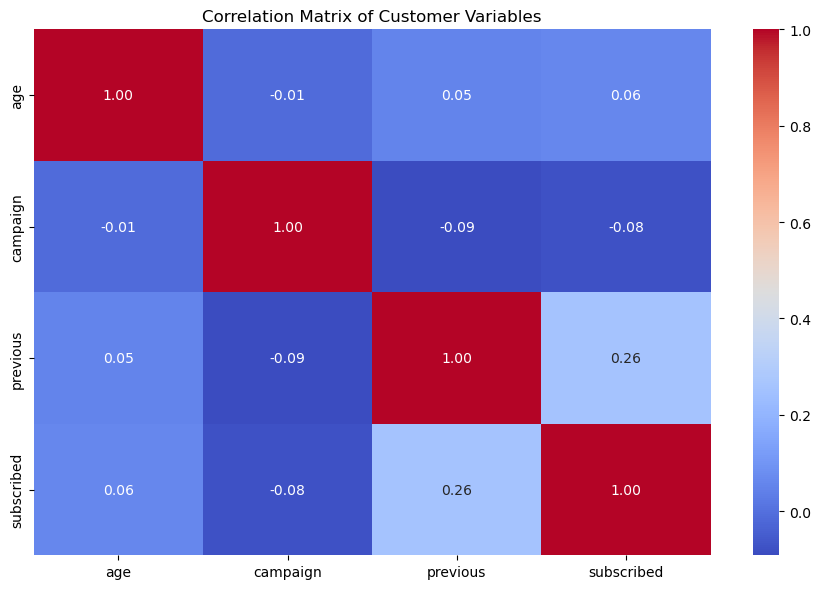

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Customer Variables')
plt.tight_layout()
plt.show()

In [93]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y',
 'age_group',
 'subscribed']

In [94]:
df[['age', 'campaign', 'previous', 'poutcome', 'contact', 'y']].head(10)

,age,campaign,previous,poutcome,contact,y
0,30,2,0,nonexistent,cellular,no
1,39,4,0,nonexistent,telephone,no
2,25,1,0,nonexistent,telephone,no
3,38,3,0,nonexistent,telephone,no
4,47,1,0,nonexistent,cellular,no
5,32,3,2,failure,cellular,no
6,32,4,0,nonexistent,cellular,no
7,41,2,0,nonexistent,cellular,no
8,31,1,1,failure,cellular,no
9,35,1,0,nonexistent,telephone,no


In [95]:
df['subscribed'] = (df['y'] == 'yes').astype(int)

In [96]:
df[['y', 'subscribed']].head(10)

,y,subscribed
0,no,0
1,no,0
2,no,0
3,no,0
4,no,0
5,no,0
6,no,0
7,no,0
8,no,0
9,no,0


In [97]:
df[
    ['age', 'campaign', 'previous', 'poutcome', 'contact', 'subscribed']
].isnull().sum()

age           0
campaign      0
previous      0
poutcome      0
contact       0
subscribed    0
dtype: int64

In [98]:
print(df['poutcome'].unique())

print(df['contact'].unique())

['nonexistent' 'failure' 'success']
['cellular' 'telephone']


In [99]:
model_data = df[
    ['age', 'campaign', 'previous', 'poutcome', 'contact', 'subscribed']
].copy()

model_data = pd.get_dummies(
    model_data,
    columns=['poutcome', 'contact'],
    drop_first=True,
    dtype=int
)

model_data.head()

,age,campaign,previous,subscribed,poutcome_nonexistent,poutcome_success,contact_telephone
0,30,2,0,0,1,0,0
1,39,4,0,0,1,0,1
2,25,1,0,0,1,0,1
3,38,3,0,0,1,0,1
4,47,1,0,0,1,0,0


In [100]:
model_data.columns.tolist()

['age',
 'campaign',
 'previous',
 'subscribed',
 'poutcome_nonexistent',
 'poutcome_success',
 'contact_telephone']

In [101]:
model_data.iloc[:5].to_dict('records')

[{'age': 30,
  'campaign': 2,
  'previous': 0,
  'subscribed': 0,
  'poutcome_nonexistent': 1,
  'poutcome_success': 0,
  'contact_telephone': 0},
 {'age': 39,
  'campaign': 4,
  'previous': 0,
  'subscribed': 0,
  'poutcome_nonexistent': 1,
  'poutcome_success': 0,
  'contact_telephone': 1},
 {'age': 25,
  'campaign': 1,
  'previous': 0,
  'subscribed': 0,
  'poutcome_nonexistent': 1,
  'poutcome_success': 0,
  'contact_telephone': 1},
 {'age': 38,
  'campaign': 3,
  'previous': 0,
  'subscribed': 0,
  'poutcome_nonexistent': 1,
  'poutcome_success': 0,
  'contact_telephone': 1},
 {'age': 47,
  'campaign': 1,
  'previous': 0,
  'subscribed': 0,
  'poutcome_nonexistent': 1,
  'poutcome_success': 0,
  'contact_telephone': 0}]

In [102]:
X = model_data.drop('subscribed', axis=1)

y = model_data['subscribed']

In [103]:
print("Predictor variables:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Predictor variables:
   age  campaign  previous  poutcome_nonexistent  poutcome_success  \
0   30         2         0                     1                 0   
1   39         4         0                     1                 0   
2   25         1         0                     1                 0   
3   38         3         0                     1                 0   
4   47         1         0                     1                 0   

   contact_telephone  
0                  0  
1                  1  
2                  1  
3                  1  
4                  0  

Target variable:
0    0
1    0
2    0
3    0
4    0
Name: subscribed, dtype: int32


In [104]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [105]:
print("Original dataset:", X.shape)
print("Training dataset:", X_train.shape)
print("Testing dataset:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Original dataset: (4119, 6)
Training dataset: (3295, 6)
Testing dataset: (824, 6)

Training target distribution:
0    89.044006
1    10.955994
Name: subscribed, dtype: float64

Testing target distribution:
0    89.07767
1    10.92233
Name: subscribed, dtype: float64


In [106]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns
numeric_columns = ['age', 'campaign', 'previous']

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = X_train.copy()
X_train_scaled[numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

# Transform testing data using the same scaler
X_test_scaled = X_test.copy()
X_test_scaled[numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

In [107]:
from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(max_iter=1000)

# Train the model using training data
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [108]:
# Predict subscription outcomes
y_pred = log_model.predict(X_test_scaled)

# Predict subscription probabilities
y_probability = log_model.predict_proba(X_test_scaled)

# Display the first 10 predictions
print("Actual outcomes:")
print(y_test.head(10).values)

print("\nPredicted outcomes:")
print(y_pred[:10])

print("\nPredicted probabilities:")
print(y_probability[:10])

Actual outcomes:
[0 0 0 0 0 0 0 0 0 0]

Predicted outcomes:
[0 0 0 0 0 1 0 0 0 0]

Predicted probabilities:
[[0.85285625 0.14714375]
 [0.91520305 0.08479695]
 [0.901029   0.098971  ]
 [0.94922125 0.05077875]
 [0.8819881  0.1180119 ]
 [0.49811487 0.50188513]
 [0.89177608 0.10822392]
 [0.91728391 0.08271609]
 [0.95097767 0.04902233]
 [0.88793885 0.11206115]]


In [109]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[729   5]
 [ 78  12]]


In [110]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.99      0.95       734
           1       0.71      0.13      0.22        90

    accuracy                           0.90       824
   macro avg       0.80      0.56      0.59       824
weighted avg       0.88      0.90      0.87       824



In [111]:
# Extract probability of subscription (class 1)
subscription_probability = log_model.predict_proba(X_test_scaled)[:, 1]

# Change classification threshold to 0.30
y_pred_30 = (subscription_probability >= 0.30).astype(int)

# Evaluate the new predictions
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_30))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_30))

Confusion Matrix:
[[726   8]
 [ 72  18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       734
           1       0.69      0.20      0.31        90

    accuracy                           0.90       824
   macro avg       0.80      0.59      0.63       824
weighted avg       0.89      0.90      0.88       824



In [112]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:

    predictions = (subscription_probability >= threshold).astype(int)

    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1
    })

threshold_analysis = pd.DataFrame(results)

threshold_analysis

,Threshold,Precision,Recall,F1_Score
0,0.10,0.180791,0.711111,0.288288
1,0.15,0.466667,0.233333,0.311111
2,0.20,0.580645,0.200000,0.297521
3,0.25,0.666667,0.200000,0.307692
4,0.30,0.692308,0.200000,0.310345
5,0.35,0.708333,0.188889,0.298246
6,0.40,0.708333,0.188889,0.298246
7,0.45,0.727273,0.177778,0.285714
8,0.50,0.705882,0.133333,0.224299


In [113]:
from sklearn.metrics import roc_auc_score, roc_curve

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, subscription_probability)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7279745685740237


In [114]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Create a new Logistic Regression model
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

# Train the model
balanced_model.fit(X_train_scaled, y_train)

# Predict customer subscription outcomes
y_pred_balanced = balanced_model.predict(X_test_scaled)

# Calculate subscription probabilities
balanced_probability = balanced_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nROC-AUC:")
print(roc_auc_score(y_test, balanced_probability))

Confusion Matrix:
[[500 234]
 [ 32  58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.68      0.79       734
           1       0.20      0.64      0.30        90

    accuracy                           0.68       824
   macro avg       0.57      0.66      0.55       824
weighted avg       0.86      0.68      0.74       824


ROC-AUC:
0.7280048440811384


In [115]:
balanced_thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

balanced_results = []

for threshold in balanced_thresholds:

    predictions = (balanced_probability >= threshold).astype(int)

    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    balanced_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1
    })

balanced_threshold_analysis = pd.DataFrame(balanced_results)

balanced_threshold_analysis

,Threshold,Precision,Recall,F1_Score
0,0.20,0.111809,0.988889,0.200903
1,0.25,0.113842,0.977778,0.203940
2,0.30,0.122449,0.933333,0.216495
3,0.35,0.149723,0.900000,0.256735
4,0.40,0.152749,0.833333,0.258176
5,0.45,0.164352,0.788889,0.272031
6,0.50,0.198630,0.644444,0.303665


In [116]:
import pandas as pd
import numpy as np

# Extract model coefficients
coefficient_analysis = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': balanced_model.coef_[0]
})

# Calculate odds ratios
coefficient_analysis['Odds_Ratio'] = np.exp(
    coefficient_analysis['Coefficient']
)

# Sort by coefficient
coefficient_analysis = coefficient_analysis.sort_values(
    by='Coefficient',
    ascending=False
)

coefficient_analysis

,Feature,Coefficient,Odds_Ratio
4,poutcome_success,1.978752,7.233708
3,poutcome_nonexistent,0.559732,1.750203
2,previous,0.427229,1.533004
0,age,0.079809,1.083080
1,campaign,-0.308790,0.734335
5,contact_telephone,-0.786957,0.455228


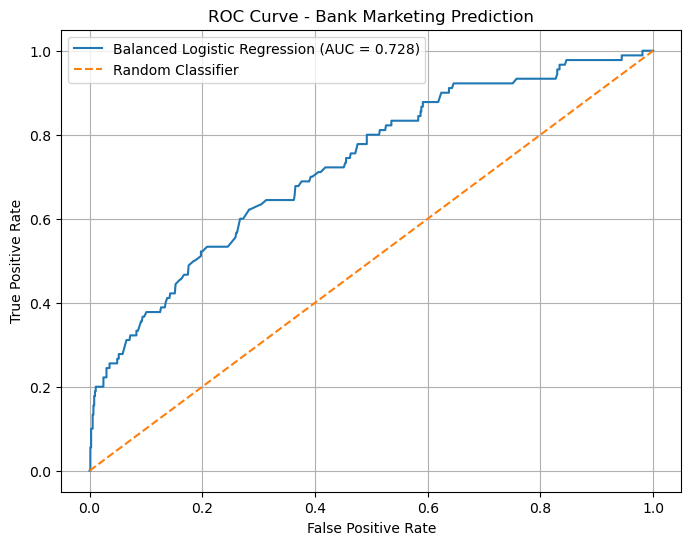

In [117]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(
    y_test,
    balanced_probability
)

# Calculate AUC
auc_score = roc_auc_score(
    y_test,
    balanced_probability
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Balanced Logistic Regression (AUC = {auc_score:.3f})'
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Bank Marketing Prediction')
plt.legend()
plt.grid(True)

plt.show()

In [118]:
# Create feature importance table
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': np.abs(balanced_model.coef_[0])
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                Feature  Importance
4      poutcome_success    1.978752
5     contact_telephone    0.786957
3  poutcome_nonexistent    0.559732
2              previous    0.427229
1              campaign    0.308790
0                   age    0.079809


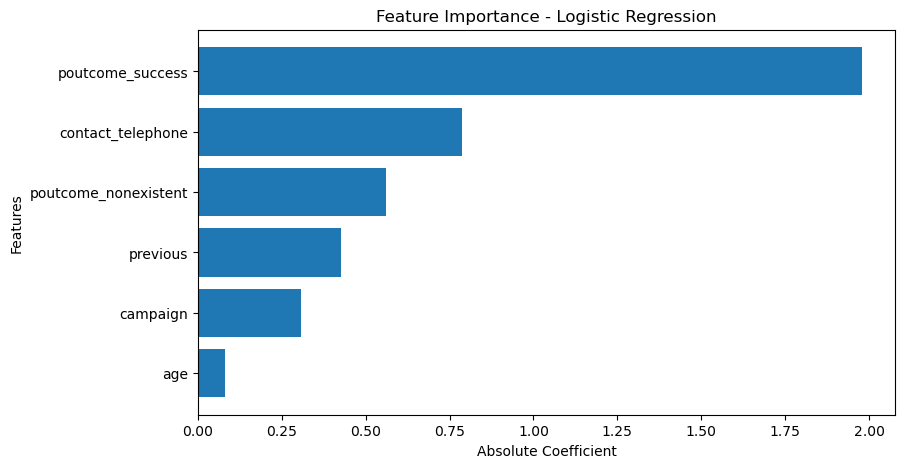

In [119]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Absolute Coefficient')
plt.ylabel('Features')
plt.title('Feature Importance - Logistic Regression')
plt.gca().invert_yaxis()

plt.show()

In [120]:
pre_campaign_data = df[
    ['age', 'previous', 'poutcome', 'contact', 'subscribed']
].copy()

pre_campaign_data = pd.get_dummies(
    pre_campaign_data,
    columns=['poutcome', 'contact'],
    drop_first=True,
    dtype=int
)

X_pre = pre_campaign_data.drop('subscribed', axis=1)
y_pre = pre_campaign_data['subscribed']

print("Dataset shape:", pre_campaign_data.shape)

print("\nPredictor columns:")
print(X_pre.columns.tolist())

print("\nFirst five records:")
print(pre_campaign_data.head())

Dataset shape: (4119, 6)

Predictor columns:
['age', 'previous', 'poutcome_nonexistent', 'poutcome_success', 'contact_telephone']

First five records:
   age  previous  subscribed  poutcome_nonexistent  poutcome_success  \
0   30         0           0                     1                 0   
1   39         0           0                     1                 0   
2   25         0           0                     1                 0   
3   38         0           0                     1                 0   
4   47         0           0                     1                 0   

   contact_telephone  
0                  0  
1                  1  
2                  1  
3                  1  
4                  0  


In [121]:
from sklearn.model_selection import train_test_split

X_pre_train, X_pre_test, y_pre_train, y_pre_test = train_test_split(
    X_pre,
    y_pre,
    test_size=0.20,
    random_state=42,
    stratify=y_pre
)

print("Original dataset:", X_pre.shape)
print("Training dataset:", X_pre_train.shape)
print("Testing dataset:", X_pre_test.shape)

print("\nTraining target distribution:")
print(y_pre_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_pre_test.value_counts(normalize=True) * 100)

Original dataset: (4119, 5)
Training dataset: (3295, 5)
Testing dataset: (824, 5)

Training target distribution:
0    89.044006
1    10.955994
Name: subscribed, dtype: float64

Testing target distribution:
0    89.07767
1    10.92233
Name: subscribed, dtype: float64


In [122]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns
numeric_columns_pre = ['age', 'previous']

# Create scaler
scaler_pre = StandardScaler()

# Copy training and testing datasets
X_pre_train_scaled = X_pre_train.copy()
X_pre_test_scaled = X_pre_test.copy()

# Fit and transform training data
X_pre_train_scaled[numeric_columns_pre] = scaler_pre.fit_transform(
    X_pre_train[numeric_columns_pre]
)

# Transform testing data
X_pre_test_scaled[numeric_columns_pre] = scaler_pre.transform(
    X_pre_test[numeric_columns_pre]
)

In [123]:
from sklearn.linear_model import LogisticRegression

# Create pre-campaign model
pre_campaign_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

# Train model
pre_campaign_model.fit(
    X_pre_train_scaled,
    y_pre_train
)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [124]:
# Predict subscription outcomes
y_pre_pred = pre_campaign_model.predict(X_pre_test_scaled)

# Predict subscription probabilities
y_pre_probability = pre_campaign_model.predict_proba(
    X_pre_test_scaled
)[:, 1]

# Display first 10 predictions
print("Actual outcomes:")
print(y_pre_test.head(10).values)

print("\nPredicted outcomes:")
print(y_pre_pred[:10])

print("\nSubscription probabilities:")
print(y_pre_probability[:10])

Actual outcomes:
[0 0 0 0 0 0 0 0 0 0]

Predicted outcomes:
[1 0 0 0 1 1 0 1 0 0]

Subscription probabilities:
[0.54811348 0.45498895 0.46863254 0.28377446 0.54227968 0.89557023
 0.46472868 0.50584329 0.29998075 0.47449538]


In [125]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print("Confusion Matrix:")
print(confusion_matrix(y_pre_test, y_pre_pred))

print("\nClassification Report:")
print(classification_report(y_pre_test, y_pre_pred))

print("\nROC-AUC:")
print(roc_auc_score(y_pre_test, y_pre_probability))

Confusion Matrix:
[[591 143]
 [ 43  47]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.86       734
           1       0.25      0.52      0.34        90

    accuracy                           0.77       824
   macro avg       0.59      0.66      0.60       824
weighted avg       0.86      0.77      0.81       824


ROC-AUC:
0.7240160460187709
